# Segmentation semantique : la forme et la surface de chaque defaut

Un masque de classes par pixel (U-Net, DeepLabV3+, FPN... de segmentation_models_pytorch),
un encodeur pre-entraine (resnet18 ImageNet) et une perte CE + Dice qui resiste a la domination
du fond. Donnees : Magnetic Tile (masques fournis), essai court sur CPU.

In [1]:
from pathlib import Path  # Path : represente un chemin de fichier, fonctionne sous Windows comme sous Linux

import matplotlib.pyplot as plt  # matplotlib : trace les figures
import numpy as np  # numpy : calcul sur des tableaux de nombres (une image = un tableau)
from IPython.display import Image, display  # affiche dans le notebook une image PNG deja enregistree sur disque

from vtb.core.config import load_config  # lit le fichier YAML de l'experience et verifie chaque reglage
from vtb.core.experiment import start  # prepare l'experience : dossier de sortie, journal, graines, choix CPU / GPU
from vtb.preprocess import Pipeline  # enchaine les operations de pretraitement decrites dans le YAML
from vtb.split import load_split  # relit le decoupage train / val / test enregistre dans split.csv
from vtb.tasks.segmentation import workflow  # les etapes de la recette segmentation (prepare, train, evaluate, predict, export)
from vtb.tasks.segmentation.config import SegmentationConfig  # modele de configuration : les cles autorisees dans le YAML

# jeu de donnees PyTorch (image + masque de classes) ; noms des classes de pixels (fond en premier)
from vtb.tasks.segmentation.data import SegmentationDataset, class_names_for

config = load_config("recipes/segmentation/configs/quick.yaml", SegmentationConfig)  # config d'essai rapide
# meme config, mais les sorties vont dans un dossier a part pour ne pas melanger avec celles des scripts
config = config.model_copy(update={"runtime": config.runtime.model_copy(update={"output_dir": "outputs/segmentation/notebook"})})
output, device = start(config, "notebook")  # cree le dossier de sortie, le journal, fixe les graines ; device = CPU ou GPU

2026-11-05 19:40:37,962 | INFO | notebook | sortie outputs/segmentation/notebook | device cpu


## 1. Images et masques

Le masque est lu, encode en indices de classe (`mask_mode`), puis ramene a la taille de l'image
pretraitee AU PLUS PROCHE VOISIN (une interpolation creerait des classes intermediaires).

split        test  train  val
label                        
MT_Blowhole     5     15    3
MT_Break        2      6    1
MT_Crack        2      6    2
MT_Fray         0      2    0
MT_Free        28     90   21
MT_Uneven       3     11    3


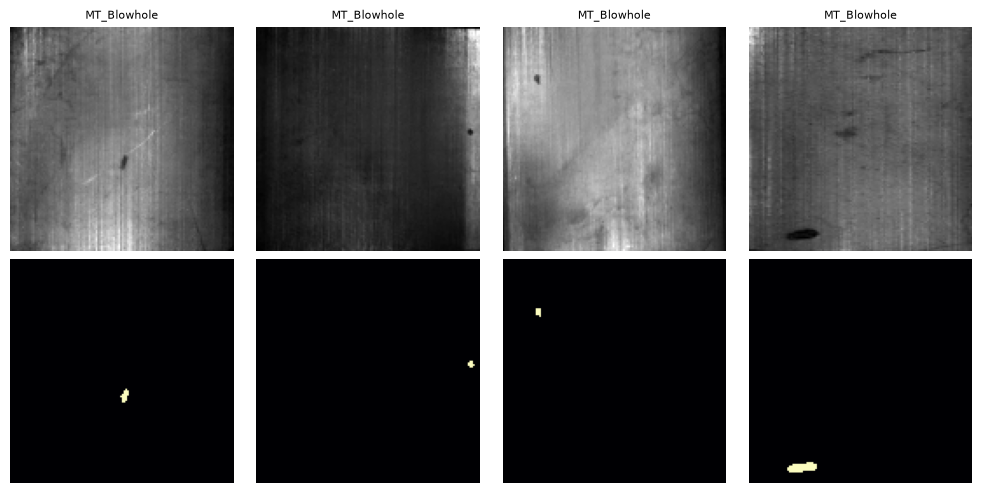

part de pixels de defaut : 0.002


In [2]:
if not Path(config.split.file).exists():  # si le decoupage n'a pas encore ete fait
    workflow.prepare(config)  # catalogue image + masque, puis decoupage train / val / test
split = load_split(config.split.file)  # relit le decoupage : une ligne par image (path, mask_path, label, split...)
print(split.groupby(["label", "split"]).size().unstack(fill_value=0))  # tableau : nombre d'images par etiquette et par partie
names = class_names_for(split, config.mask_mode, config.class_names, config.normal_labels)  # classes de pixels, fond en premier
# jeu de donnees des images de train : pretraitement du YAML, lecture en couleur ou gris, conversion des masques en classes
dataset = SegmentationDataset(split[split["split"] == "train"], Pipeline(config.preprocess), config.data.color, config.mask_mode, names)
fig, axes = plt.subplots(2, 4, figsize=(10, 5))  # grille 2 lignes (image, masque) x 4 exemples
# numeros des 4 premieres images dont le masque contient au moins un pixel de defaut (load(i) renvoie (image, masque))
picked = [i for i in range(len(dataset)) if dataset.load(i)[1].any()][:4]
for k, i in enumerate(picked):  # pour chaque exemple choisi ; k = numero de colonne, i = numero dans le jeu
    image, mask = dataset.load(i)  # image pretraitee et masque de classes (un numero de classe par pixel)
    axes[0, k].imshow(image, cmap="gray")  # 1re ligne : l'image
    axes[1, k].imshow(mask, cmap="magma", vmin=0, vmax=len(names) - 1)  # 2e ligne : le masque, une couleur par classe
    axes[0, k].set_title(dataset.labels[i], fontsize=8)  # titre : l'etiquette de l'image
for ax in axes.ravel():  # pour chaque case de la grille
    ax.axis("off")  # masque les axes gradues
plt.tight_layout()  # resserre les cases
plt.show()  # affiche la figure
# part moyenne des pixels de defaut sur ces exemples : le fond domine, d'ou la perte Dice (sensible aux petites zones)
print("part de pixels de defaut :", round(float(np.mean([(dataset.load(i)[1] > 0).mean() for i in picked])), 3))

## 2. Entrainer (2 epoques) puis evaluer

Criteres : IoU et Dice par classe (moyenne sur les classes de DEFAUT, le fond gonflerait tout)
et decision par image (au moins `min_defect_area` pixels de defaut).

2026-11-05 19:40:39,837 | INFO | encodeur resnet18 : poids ImageNet torchvision (1 canal/canaux, repetition x3)


2026-11-05 19:40:39,840 | INFO | unet / resnet18 | 2 classes ['background', 'defect'] | 1 canal/canaux | 14,328,354 parametres


2026-11-05 19:42:03,700 | INFO | epoque  1 | perte 1.3415 | val mIoU 0.321 | mIoU defauts 0.0206 | 84s | meilleur


2026-11-05 19:42:52,788 | INFO | epoque  2 | perte 0.9618 | val mIoU 0.473 | mIoU defauts 0.0057 | 49s


2026-11-05 19:42:52,793 | INFO | entrainement : 133.0 s


2026-11-05 19:43:02,376 | INFO | prediction du test : 8.6 s


2026-11-05 19:43:03,500 | INFO | test (40 images) : mIoU defauts 0.0089 | Dice defauts 0.0176 | rappel image 1.0 | fausses alarmes image 1.0


{'miou_defects': 0.0089, 'mdice_defects': 0.0176, 'image_recall': 1.0, 'image_false_alarm_rate': 1.0}


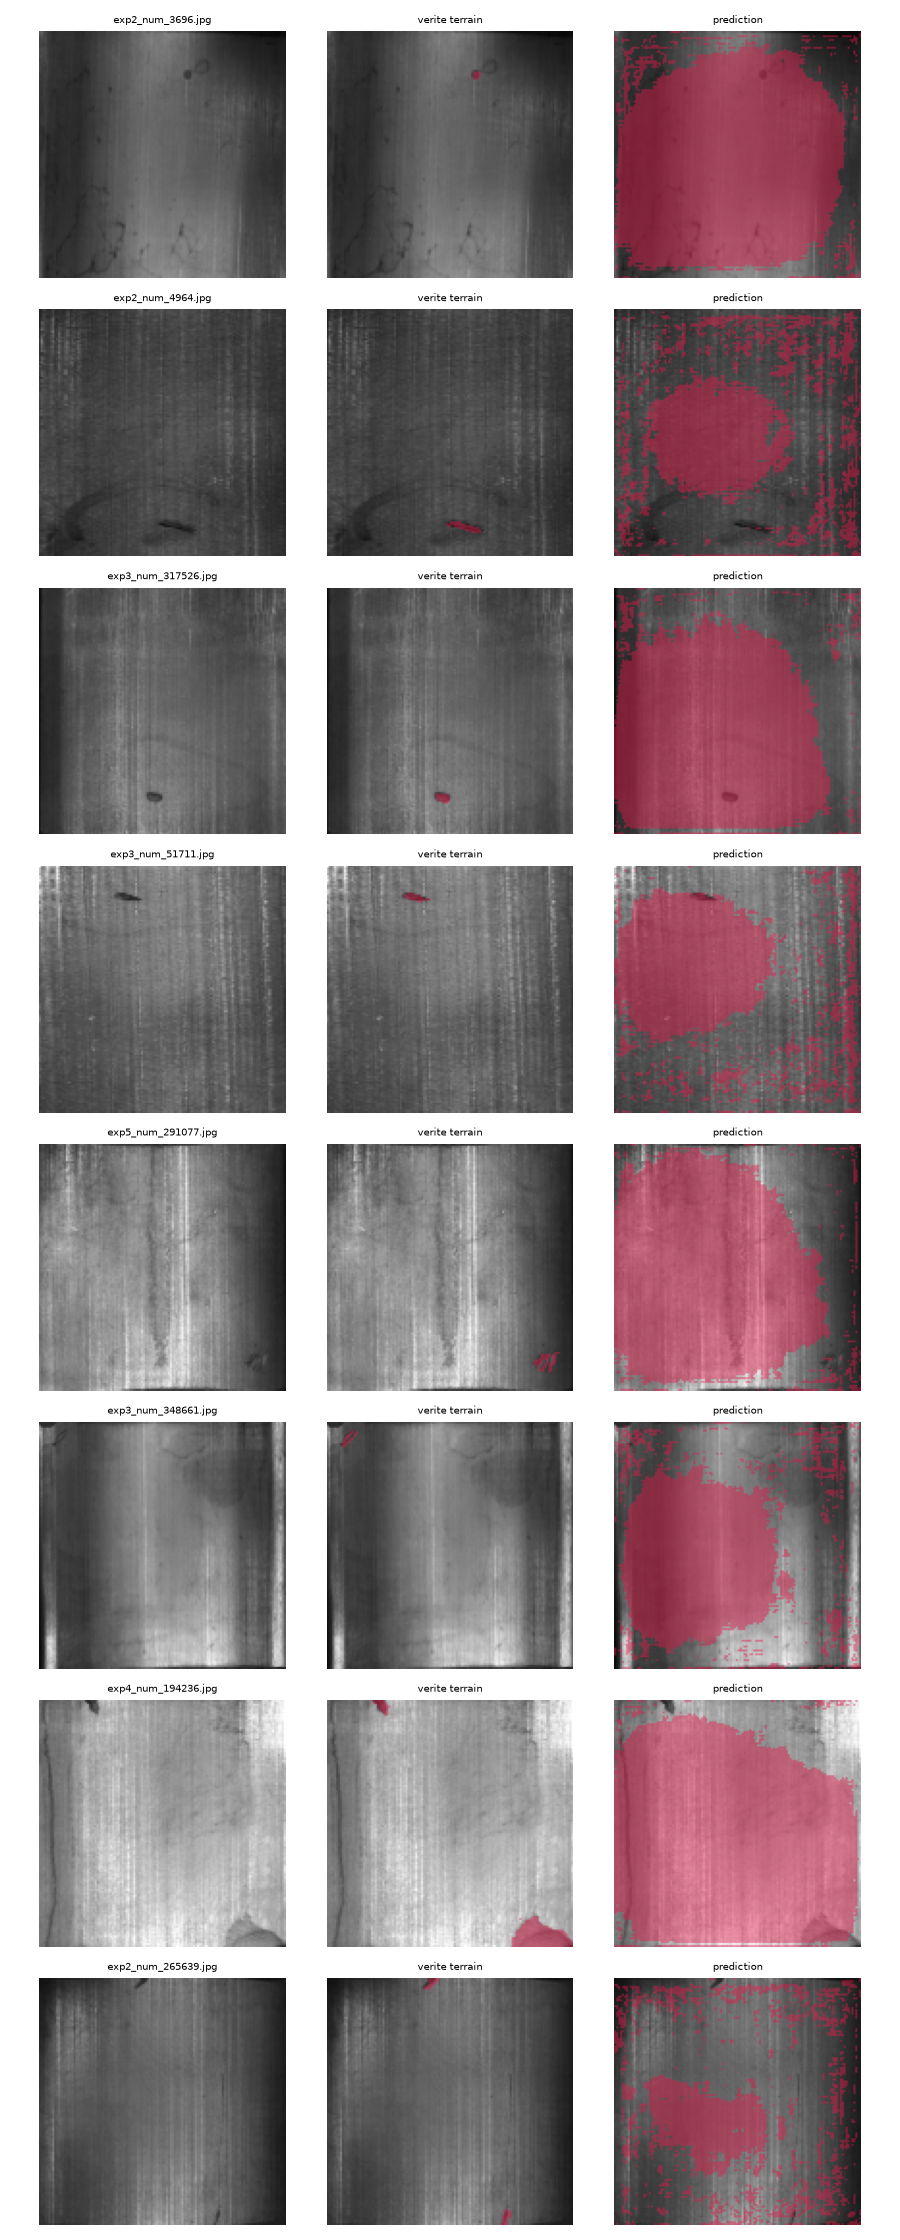

In [3]:
summary = workflow.train(config, output, device)  # entraine le reseau ; renvoie un resume (meilleure epoque, duree...)
metrics = workflow.evaluate(config, output, device)  # mesures sur le jeu de test
# mIoU et mDice moyens sur les classes de defaut, rappel et fausses alarmes de la decision par image
print({k: metrics[k] for k in ("miou_defects", "mdice_defects", "image_recall", "image_false_alarm_rate")})
display(Image(str(output / "test_predictions.png"), width=560))  # galerie : images de test, vrais masques, masques predits

## 3. Exporter : normalisation et softmax sont DANS le modele

Le programme de production envoie une image dans [0, 1] (1 canal ici : l'image grise est
copiee sur 3 canaux a l'interieur du modele, donc la reponse des poids ImageNet est exacte).

In [4]:
card = workflow.export(config, output)  # export ONNX verifie ; renvoie la carte du modele (model_card.json)
print(card.input.model_dump())  # entree attendue par le modele : taille, nombre de canaux, plage de valeurs...
print(card.postprocess)  # ce que le programme de production doit faire des sorties (ex. : prendre la classe la plus probable)

[torch.onnx] Obtain model graph for `Segmenter([...]` with `torch.export.export(..., strict=False)`...


[torch.onnx] Obtain model graph for `Segmenter([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...


[torch.onnx] Optimize the ONNX graph... ✅


2026-11-05 19:43:09,488 | INFO | ONNX ecrit : outputs/segmentation/notebook/model.onnx (57.5 Mo, lot dynamique)


2026-11-05 19:43:10,209 | INFO | verification ONNX OK : {'output_0_max_abs_diff': '1.93e-05', 'output_0_scale': '1.00e+00', 'batch_size': 3}


2026-11-05 19:43:12,141 | INFO | OpenVINO ecrit : outputs/segmentation/notebook/model.xml


2026-11-05 19:43:22,401 | INFO | latence : {'torch_cpu_ms': 970.86, 'batch': 1, 'onnxruntime_cpu_ms': 43.58, 'openvino_cpu_ms': 13.31}


{'name': 'input', 'layout': 'NCHW', 'height': 128, 'width': 128, 'channels': 1, 'color': 'GRAY', 'dtype': 'float32', 'scale': 'divide by 255 (8 bits) or 65535 (16 bits)', 'mean': [], 'std': [], 'resize': 'stretch', 'letterbox_pad_value': None, 'dynamic_batch': True, 'read_color': 'gray'}
{'classes': '2 classes : pixel defaut si probabilities[1] > defect_probability ; sinon argmax sur les classes', 'decision': 'image signalee si le nombre de pixels de defaut >= min_defect_area', 'normalization': 'incluse dans le modele (entree dans [0, 1])'}
